# 图像分类数据集
:label:`sec_fashion_mnist`

(**MNIST数据集**) :cite:`LeCun.Bottou.Bengio.ea.1998`
(**是图像分类中广泛使用的数据集之一，但作为基准数据集过于简单。
我们将使用类似但更复杂的Fashion-MNIST数据集**) :cite:`Xiao.Rasul.Vollgraf.2017`。


In [1]:
%matplotlib inline
import torch
import torchvision
from torch.utils import data
from torchvision import transforms
from d2l import torch as d2l

d2l.use_svg_display()

## 读取数据集

我们可以[**通过框架中的内置函数将Fashion-MNIST数据集下载并读取到内存中**]。


In [2]:
# 通过ToTensor实例将图像数据从PIL类型变换成32位浮点数格式，
# 并除以255使得所有像素的数值均在0～1之间
trans = transforms.ToTensor() #transform=trans 每张图转成张量（顺便除以 255） 
mnist_train = torchvision.datasets.FashionMNIST(  # 下载/读取训练集
    root="../data", train=True, transform=trans, download=True) # 图片存到上一级目录的 data 文件夹  每张图都过一遍 trans 这台机器
mnist_test = torchvision.datasets.FashionMNIST( #测试数据集
    root="../data", train=False, transform=trans, download=True)

Fashion-MNIST由10个类别的图像组成，
每个类别由*训练数据集*（train dataset）中的6000张图像
和*测试数据集*（test dataset）中的1000张图像组成。
因此，训练集和测试集分别包含60000和10000张图像。
测试数据集不会用于训练，只用于评估模型性能。


In [3]:
len(mnist_train), len(mnist_test) # 数训练集和测试集的图片数量

(60000, 10000)

每个输入图像的高度和宽度均为28像素。
数据集由灰度图像组成，其通道数为1。
为了简洁起见，本书将高度$h$像素、宽度$w$像素图像的形状记为$h \times w$或（$h$,$w$）。


In [4]:
mnist_train[0][0].shape# 第 0 个样本 → 返回 (图片, 标签) 两样东西 # 再取第 0 个 → 只要图片 # 看图片的形状

torch.Size([1, 28, 28])

[~~两个可视化数据集的函数~~]

Fashion-MNIST中包含的10个类别，分别为t-shirt（T恤）、trouser（裤子）、pullover（套衫）、dress（连衣裙）、coat（外套）、sandal（凉鞋）、shirt（衬衫）、sneaker（运动鞋）、bag（包）和ankle boot（短靴）。
以下函数用于在数字标签索引及其文本名称之间进行转换。


In [5]:
def get_fashion_mnist_labels(labels):  #@save  # 定义函数，参数 labels 是一串数字
    """返回Fashion-MNIST数据集的文本标签"""
    text_labels = ['t-shirt', 'trouser', 'pullover', 'dress', 'coat', # 10 个类别的名字
                   'sandal', 'shirt', 'sneaker', 'bag', 'ankle boot']
    return [text_labels[int(i)] for i in labels]  # 把每个数字翻译成对应的名字

我们现在可以创建一个函数来可视化这些样本。


In [6]:
def show_images(imgs, num_rows, num_cols, titles=None, scale=1.5):  #@save
    """绘制图像列表"""
    figsize = (num_cols * scale, num_rows * scale) # 算整张大图的尺寸
    _, axes = d2l.plt.subplots(num_rows, num_cols, figsize=figsize) # 建画布 + 一堆小格子
    axes = axes.flatten() # 把格子数组拍平成一维
    for i, (ax, img) in enumerate(zip(axes, imgs)):  # 格子 和 图片 一一配对
        if torch.is_tensor(img):  # 如果是张量
            # 图片张量
            ax.imshow(img.numpy())   # 转成 numpy 再画
        else:
            # PIL图片
            ax.imshow(img)   # 如果是 PIL图片直接画
        ax.axes.get_xaxis().set_visible(False)   # 隐藏 x 轴刻度
        ax.axes.get_yaxis().set_visible(False)   # 隐藏 y 轴刻度
        if titles: # 有标题的话
            ax.set_title(titles[i])  # 给这张图加标题
    return axes

以下是训练数据集中前[**几个样本的图像及其相应的标签**]。


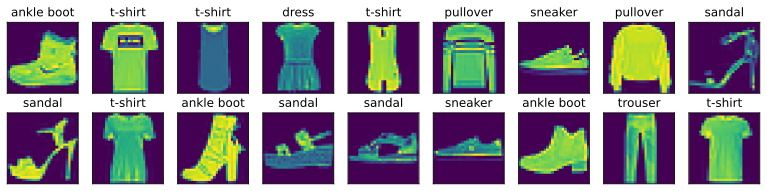

In [7]:
X, y = next(iter(data.DataLoader(mnist_train, batch_size=18))) # 拿 18 张图
show_images(X.reshape(18, 28, 28), 2, 9, titles=get_fashion_mnist_labels(y));  # 18 张图,排2行9列 # 标题用文字标签

## 读取小批量

为了使我们在读取训练集和测试集时更容易，我们使用内置的数据迭代器，而不是从零开始创建。
回顾一下，在每次迭代中，数据加载器每次都会[**读取一小批量数据，大小为`batch_size`**]。
通过内置数据迭代器，我们可以随机打乱了所有样本，从而无偏见地读取小批量。


In [10]:
batch_size = 256 # 每批拿 256 张图

def get_dataloader_workers():  #@save # 定义函数：决定开几个进程读数据
    """使用4个进程来读取数据"""
    return 0 # 原本是返回 4（Mac/Linux 用；Windows 要改成 0）

train_iter = data.DataLoader(mnist_train, batch_size, shuffle=True,  # 造训练集的“发牌机” # 数据源：60000 张训练图
                             num_workers=get_dataloader_workers())

我们看一下读取训练数据所需的时间。


In [12]:
timer = d2l.Timer() # 造一个计时器，开始计时
for X, y in train_iter:  # 把每一批数据都取出来
    continue  # 取出来但什么都不做（空转）
f'{timer.stop():.2f} sec' # 停止计时，输出秒数（保留 2 位小数）

'4.01 sec'

## 整合所有组件

现在我们[**定义`load_data_fashion_mnist`函数**]，用于获取和读取Fashion-MNIST数据集。
这个函数返回训练集和验证集的数据迭代器。
此外，这个函数还接受一个可选参数`resize`，用来将图像大小调整为另一种形状。


In [13]:
def load_data_fashion_mnist(batch_size, resize=None):  #@save
    """下载Fashion-MNIST数据集，然后将其加载到内存中"""
    trans = [transforms.ToTensor()]  # 先把图转成张量
    if resize:
        trans.insert(0, transforms.Resize(resize)) # 在最前面插一步：先把图缩放到指定大小
    trans = transforms.Compose(trans)  # 把多道工序串成一条流水线，按顺序执行
    mnist_train = torchvision.datasets.FashionMNIST(  # 下载训练集
        root="../data", train=True, transform=trans, download=True) 
    mnist_test = torchvision.datasets.FashionMNIST( # 下载测试集
        root="../data", train=False, transform=trans, download=True)
    return (data.DataLoader(mnist_train, batch_size, shuffle=True, # 训练集：打乱顺序，分批发
                            num_workers=get_dataloader_workers()),
            data.DataLoader(mnist_test, batch_size, shuffle=False,
                            num_workers=get_dataloader_workers())) # 测试集：不打乱，分批发

下面，我们通过指定`resize`参数来测试`load_data_fashion_mnist`函数的图像大小调整功能。


In [14]:
train_iter, test_iter = load_data_fashion_mnist(32, resize=64)# 一键拿到两个迭代器
for X, y in train_iter: # 每一批：X 是 256 张图，y 是 256 个标签
    print(X.shape, X.dtype, y.shape, y.dtype)
    break

torch.Size([32, 1, 64, 64]) torch.float32 torch.Size([32]) torch.int64


我们现在已经准备好使用Fashion-MNIST数据集，便于下面的章节调用来评估各种分类算法。

## 小结

* Fashion-MNIST是一个服装分类数据集，由10个类别的图像组成。我们将在后续章节中使用此数据集来评估各种分类算法。
* 我们将高度$h$像素，宽度$w$像素图像的形状记为$h \times w$或（$h$,$w$）。
* 数据迭代器是获得更高性能的关键组件。依靠实现良好的数据迭代器，利用高性能计算来避免减慢训练过程。

## 练习

1. 减少`batch_size`（如减少到1）是否会影响读取性能？
1. 数据迭代器的性能非常重要。当前的实现足够快吗？探索各种选择来改进它。
1. 查阅框架的在线API文档。还有哪些其他数据集可用？


# 做练习

In [15]:
#练习一
# batch_size = 1
train_iter_1 = data.DataLoader(mnist_train, 1, shuffle=True, num_workers=0)   # 每批 1 张
timer = d2l.Timer()                                                          # 开始计时
for X, y in train_iter_1:                                                    # 全部读一遍
    continue                                                                 # 空转
print(f'batch_size=1: {timer.stop():.2f} sec')                               # 打印耗时

# batch_size = 256
train_iter_256 = data.DataLoader(mnist_train, 256, shuffle=True, num_workers=0)  # 每批 256 张
timer = d2l.Timer()                                                             # 重新计时
for X, y in train_iter_256:                                                     # 全部读一遍
    continue                                                                    # 空转
print(f'batch_size=256: {timer.stop():.2f} sec')                                # 打印耗时

batch_size=1: 5.74 sec
batch_size=256: 3.41 sec


# Day 14：3.5 图像分类数据集 学习笔记

## 知识点大白话总结（我的小抄）

- **Fashion-MNIST**：10 类衣服的图片集，训练集 6 万张、测试集 1 万张，每张 28×28 灰度图。
- **为什么要它**：手写数字 MNIST 太简单，Fashion-MNIST 更难一点，适合练手。
- **`train=True/False`**：`True` 拿训练集（学习用），`False` 拿测试集（考试用），两者不重叠。
- **`ToTensor()`**：把 PIL 图片转成张量，像素从 0~255 除以 255 变成 0~1。
- **`transform=trans`**：把“转换机器”装到数据集上，每张图取出来时自动过一遍。
- **`mnist_train[0]`**：返回一个元组 `(图片, 标签)`；`[0][0]` 是图片，`[0][1]` 是标签。
- **`get_fashion_mnist_labels`**：把数字标签（0~9）翻译成文字（T恤、裤子……），方便看。
- **`DataLoader`**：分批发牌机，每次给 `batch_size` 张图，`shuffle=True` 每轮打乱。
- **`num_workers`**：开几个进程读数据；Windows 必须用 `0`，不然容易报错。
- **`load_data_fashion_mnist`**：整合函数，一步拿到训练集和测试集两个迭代器。
- **`Timer`**：测“把数据完整读一遍要多久”，一般 1~3 秒正常。

## 今天遇到的坑与疑问

1. **`show_images` 看不懂**：里面全是 matplotlib 画图 API，80% 不用会写，复制粘贴即可，先跳过。
2. **`mnist_train[0][0]` 两个 `[0]` 分不清**：第一个 `[0]` 取第 0 个样本，第二个 `[0]` 取这个样本里的图片（元组第 0 项）。
3. **`num_workers=4` 要不要改**：原文写 4，但我是 Windows，改成 `0` 最稳。
4. **`for X, y in train_iter: continue` 看不懂**：`continue` 是“这轮啥也不干”，整个循环只是把数据空跑一遍，用来测速。

## 今日感想（碎碎念）

- 今天空闲时间比较多,前几天有点偷懒了，所以今天就多做一点,感觉这一章还是有点难的,需要慢慢理解
- 明天开始 3.6，softmax 回归从零实现，终于要真正训练一个分类模型了。

**明天目标**：学 3.6 softmax 回归从零开始实现

[Discussions](https://discuss.d2l.ai/t/1787)
